# Homework №1


In [1]:
!pip install -q "torch>=2.2" "torchvision>=0.17" "transformers>=4.39"                 "huggingface_hub>=0.23" "av>=12" "scikit-learn>=1.4"                 "pandas>=2.0" "matplotlib>=3.8" "tqdm>=4.66"                 "pytorchvideo>=0.1.5" "fvcore>=0.1.5"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 132.7/132.7 kB 4.2 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 2.3 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.2/42.2 kB 1.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.0/35.0 MB 48.4 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.7/129.7 kB 6.4 MB/s eta 0:00:00


#### В зависимости от того, на коллабе работаете или нет будет 2 подхода:  
1) Если на колабе, то нужно подгрузить гугл диск, на котором лежат 2 архива (датасет и train-test-split)
2) Если локально или на каггле, нужно разархивировать те же 2 файла  
  
В дальнейшем иду по шагу 2

In [ ]:
from pathlib import Path
from google.colab import drive

drive.mount("/content/drive")

DRIVE_DIR = Path("/kaggle/input/datasets/vadsorokin/hmdb51/hmdb51_clean")
HMDB_ROOT = DRIVE_DIR / "hmdb51_org" 
HMDB_SPLITS = DRIVE_DIR / "test_train_splits"

# if colab
# DRIVE_DIR = Path("/content/drive/MyDrive/data/hmdb51")
# DATA_DIR = Path("/kaggle/input/datasets/vadsorokin/hmdb51/hmdb51_clean")


MODEL_X3D_CKPT = '/kaggle/input/models/vadsorokin/cv-video/pytorch/default/1/x3d_best.pt'
MODEL_VIDEOMAE_CKPT = '/kaggle/input/models/vadsorokin/cv-video/pytorch/default/1/videomae_best.pt'

In [ ]:
from __future__ import annotations

import gc
import hashlib
import json
import math
import random
import tarfile
import time
from dataclasses import dataclass
from pathlib import Path
from typing import Callable, Iterable, Literal

import subprocess
import av
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torchvision
torchvision.set_video_backend("pyav")

import torch.nn as nn
import torch.nn.functional as F
from huggingface_hub import hf_hub_download
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, Dataset
from torchvision.models import ResNet50_Weights, resnet50
from torchvision import transforms
from torchvision.models.video import R2Plus1D_18_Weights, r2plus1d_18
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = True

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("device:", DEVICE)

device: cuda


HMDB51 это датасет human motion recognition. Он содержит 6,766 видео клипов из 51 разных категорий движения, каждая из которых состоит минимум из 101 клипов. Так как в официальном train/test split нету валидации, пришлось делать самостоятельно ее. Изначально примерно 65% train, 35% test. Но от traing еще 20% откусил на валидацию  
  
Функция prepare_hmdb51 нужна как раз для того, чтобы в случае google colab можно было разархивировать все вложенные файлы (получаем HMDB_ROOT, HMDB_SPLITS)


In [ ]:
# import subprocess
# from pathlib import Path

# def prepare_hmdb51(
#     archive_dir: Path = DRIVE_DIR,
#     destination: Path = DATA_DIR,
# ) -> tuple[Path, Path]:
#     '''
#     Распаковать вложенные .rar в hmdb51_org/ и вернуть
#     (root_classes, splits_dir).
#     '''
#     HMDB_DIR = destination / "hmdb51_org"
#     SPLITS_DIR = destination / "test_train_splits"

#     if (HMDB_DIR.exists() and any(HMDB_DIR.iterdir())
#             and SPLITS_DIR.exists() and any(SPLITS_DIR.glob("*.txt"))):
#         return HMDB_DIR, SPLITS_DIR

#     hmdb_path = Path(HMDB_DIR)
#     splits_path = Path(SPLITS_DIR)
#     hmdb_path.mkdir(parents=True, exist_ok=True)
#     splits_path.mkdir(parents=True, exist_ok=True)


#     for name, target in zip(
#         ("hmdb51_org.rar", "test_train_splits.rar"),
#         (hmdb_path, splits_path),
#     ):
#         archive = archive_dir / name
#         if archive.exists():
#             subprocess.run(
#                 ["unrar", "x", "-o+", str(archive), str(target) + "/"],
#                 check=True,
#             )


#     nested_rars = [r for r in hmdb_path.glob("*.rar")]
#     print(f"nested .rar: {len(nested_rars)}")

#     for rar in sorted(nested_rars):
#         print("extracting:", rar.name)
#         subprocess.run(
#             ["unrar", "x", "-o+", str(rar), str(hmdb_path) + "/"],
#             check=True,
#         )
#         rar.unlink()

#     inner_subdir = [p for p in splits_path.iterdir() if p.is_dir()][0]           # len(inner_subdir) == 1
#     for f in inner_subdir.iterdir():
#         f.rename(splits_path / f.name)
#     inner_subdir.rmdir()

#     return HMDB_DIR, SPLITS_DIR

# HMDB_ROOT, HMDB_SPLITS = prepare_hmdb51()
# print(HMDB_ROOT, HMDB_SPLITS)

In [5]:
# ds = torchvision.datasets.HMDB51(
#     root=DATA_DIR / "hmdb51_org",
#     annotation_path=DATA_DIR / "test_train_splits",
#     frames_per_clip=16,
#     train=True,
#     fold=1
# )

# print(type(ds.video_clips))
# print(dir(ds.video_clips))

In [6]:
class HMDB51Dataset(Dataset):
    '''Wrapper around torchvision.datasets.HMDB51 with interface (clip, label, path).'''

    def __init__(
        self,
        root: Path,              # DATA_DIR / "hmdb51_org"
        annotation_path: Path,   # DATA_DIR / "test_train_splits"
        split: str,              # "train" | "test"
        frames_per_clip: int = 16,
        num_frames: int = None,  # if None return the whole clip
        step_between_clips: int = 16,
        strategy: str = 'uniform', # uniform, repeat_center
        fold: int = 1,
        transform=None,
    ):
        self._ds = torchvision.datasets.HMDB51(
            root=str(root),
            annotation_path=str(annotation_path),
            frames_per_clip=frames_per_clip,
            step_between_clips=step_between_clips,
            fold=fold,
            train=(split == "train"),
            transform=transform,
            output_format="TCHW",
        )

        self.num_frames = num_frames
        self._paths = self._build_paths()
        self.strategy = strategy
        # self._valid_indices = self._find_valid()

    # def _find_valid(self):
    #     valid = []
    #     for i in tqdm(range(len(self._ds)), desc="filtering"):
    #         try:
    #             _ = self._ds[i]
    #             valid.append(i)
    #         except RuntimeError:
    #             continue
    #     print(f"valid: {len(valid)} / {len(self._ds)}")
    #     return valid

    def _build_paths(self) -> list[str]:
        vc = self._ds.video_clips
        return [
            str(vc.video_paths[vc.get_clip_location(i)[0]])
            for i in range(len(self._ds))
        ]

    def __len__(self):
        return len(self._ds)

    def __getitem__(self, idx):
        for attempt in range(5):
            i = (idx - attempt) % len(self._ds)
            try:
                video, audio, label = self._ds[i]
                path = self._paths[i]

                if self.strategy == 'uniform':
                    if self.num_frames is not None and self.num_frames != video.shape[0]:
                        T = video.shape[0]
                        if self.num_frames == 1:
                            video = video[T // 2].unsqueeze(0)
                        else:
                            indices = torch.linspace(0, T - 1, self.num_frames).long()
                            video = video[indices]
        
                elif self.strategy == 'repeat_center':
                    T = video.shape[0]
                    center = video[T // 2]
                    video = center.unsqueeze(0).repeat(T, 1, 1, 1)

                return video, label, path
            except RuntimeError:
                pass
        raise RuntimeError(f"5 битых клипов подряд начиная с {idx}")



Datasets + tranforms

In [7]:
from torch.utils.data import Subset
import random

# frames per clip
fpc = {
    'x3d-s': 13,
    'videomae': 16
}

transform_x3d = transforms.Compose([
    transforms.Resize((160, 160)),
])

transform_videomae = transforms.Compose([
    transforms.Resize((224, 224)),
])


transform_resnet = transforms.Compose([
    transforms.Resize((224, 224)),   # ResNet-50
])

# X3D-s datasets
train_ds_x3d = HMDB51Dataset(
    root=HMDB_ROOT,
    annotation_path=HMDB_SPLITS,
    frames_per_clip=fpc['x3d-s'],
    step_between_clips=fpc['x3d-s'],
    split='train',
    transform=transform_x3d,
    fold=1,
)

test_ds_x3d = HMDB51Dataset(
    root=HMDB_ROOT,
    annotation_path=HMDB_SPLITS,
    frames_per_clip=fpc['x3d-s'],
    step_between_clips=fpc['x3d-s'],
    split='test',
    transform=transform_x3d,
    fold=1,
)

# VideoMAE datasets
train_ds_videomae = HMDB51Dataset(
    root=HMDB_ROOT,
    annotation_path=HMDB_SPLITS,
    frames_per_clip=fpc['videomae'],
    step_between_clips=fpc['videomae'],
    split='train',
    transform=transform_videomae,
    fold=1,
)
test_ds_videomae = HMDB51Dataset(
    root=HMDB_ROOT,
    annotation_path=HMDB_SPLITS,
    frames_per_clip=fpc['videomae'],
    step_between_clips=fpc['videomae'],
    split='test',
    transform=transform_videomae,
    fold=1,
)

def make_train_val_split(ds, val_ratio=0.2, seed=42):
    n = len(ds)
    idx = list(range(n))
    random.Random(seed).shuffle(idx)
    n_val = int(val_ratio * n)
    return Subset(ds, idx[n_val:]), Subset(ds, idx[:n_val])


train_ds_videomae, val_ds_videomae = make_train_val_split(train_ds_videomae)
train_ds_x3d, val_ds_x3d = make_train_val_split(train_ds_x3d)

100%|██████████| 423/423 [00:12<00:00, 34.75it/s]


In [8]:
for name, ds in [
    ("train_x3d", train_ds_x3d),
    ("val_x3d", val_ds_x3d),
    ("test_x3d", test_ds_x3d),
    ("train_videomae", train_ds_videomae),
    ("val_videomae", val_ds_videomae),
    ("test_videomae", test_ds_videomae),
]:
    print(f"{name}: {len(ds)}")

train_x3d: 20304
val_x3d: 5075
test_x3d: 10574
train_videomae: 16142
val_videomae: 4035
test_videomae: 8386


In [9]:
def probe_video(path: Path) -> dict[str, object]:
    '''Read container metadata without decoding all frames.'''
    with av.open(str(path)) as container:
        stream = container.streams.video[0]
        fps = float(stream.average_rate) if stream.average_rate else np.nan
        n_frames = int(stream.frames or 0)
        duration = n_frames / fps if fps and n_frames else np.nan
        return {
            "file": path.name,
            "class": path.parent.name,
            "fps": fps,
            "frames": n_frames,
            "duration_s": duration,
            "width": stream.width,
            "height": stream.height,
        }

sample_paths = sorted(HMDB_ROOT.glob("*/*.avi"))[:30]

metadata = pd.DataFrame(probe_video(p) for p in tqdm(sample_paths))
display(metadata.head())
display(metadata.describe(include="all").round(2))

  0%|          | 0/30 [00:00<?, ?it/s]

,file,class,fps,frames,duration_s,width,height
0,April_09_brush_hair_u_nm_np1_ba_goo_0.avi,brush_hair,30.0,409,13.633333,320,240
1,April_09_brush_hair_u_nm_np1_ba_goo_1.avi,brush_hair,30.0,395,13.166667,320,240
2,April_09_brush_hair_u_nm_np1_ba_goo_2.avi,brush_hair,30.0,323,10.766667,320,240
3,Aussie_Brunette_Brushing_Hair_II_brush_hair_u_...,brush_hair,30.0,246,8.200000,416,240
4,Aussie_Brunette_Brushing_Hair_II_brush_hair_u_...,brush_hair,30.0,159,5.300000,416,240


,file,class,fps,frames,duration_s,width,height
count,30,30,30.0,30.00,30.00,30.00,30.0
unique,30,1,NaN,NaN,NaN,NaN,NaN
top,April_09_brush_hair_u_nm_np1_ba_goo_0.avi,brush_hair,NaN,NaN,NaN,NaN,NaN
freq,1,30,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,30.0,271.00,9.03,358.40,240.0
std,NaN,NaN,0.0,134.59,4.49,47.83,0.0
min,NaN,NaN,30.0,79.00,2.63,320.00,240.0
25%,NaN,NaN,30.0,164.50,5.48,320.00,240.0
50%,NaN,NaN,30.0,251.50,8.38,320.00,240.0
75%,NaN,NaN,30.0,321.75,10.73,416.00,240.0


### 1.1. Состав датасета
Сначала посмотрим на данные до загрузки моделей.

classes: 51


  0%|          | 0/153 [00:00<?, ?it/s]

split,test,train
class,,
brush_hair,30,70
cartwheel,30,70
catch,30,70
chew,30,70
clap,30,70
climb,30,70
climb_stairs,30,70
dive,30,70
draw_sword,30,70


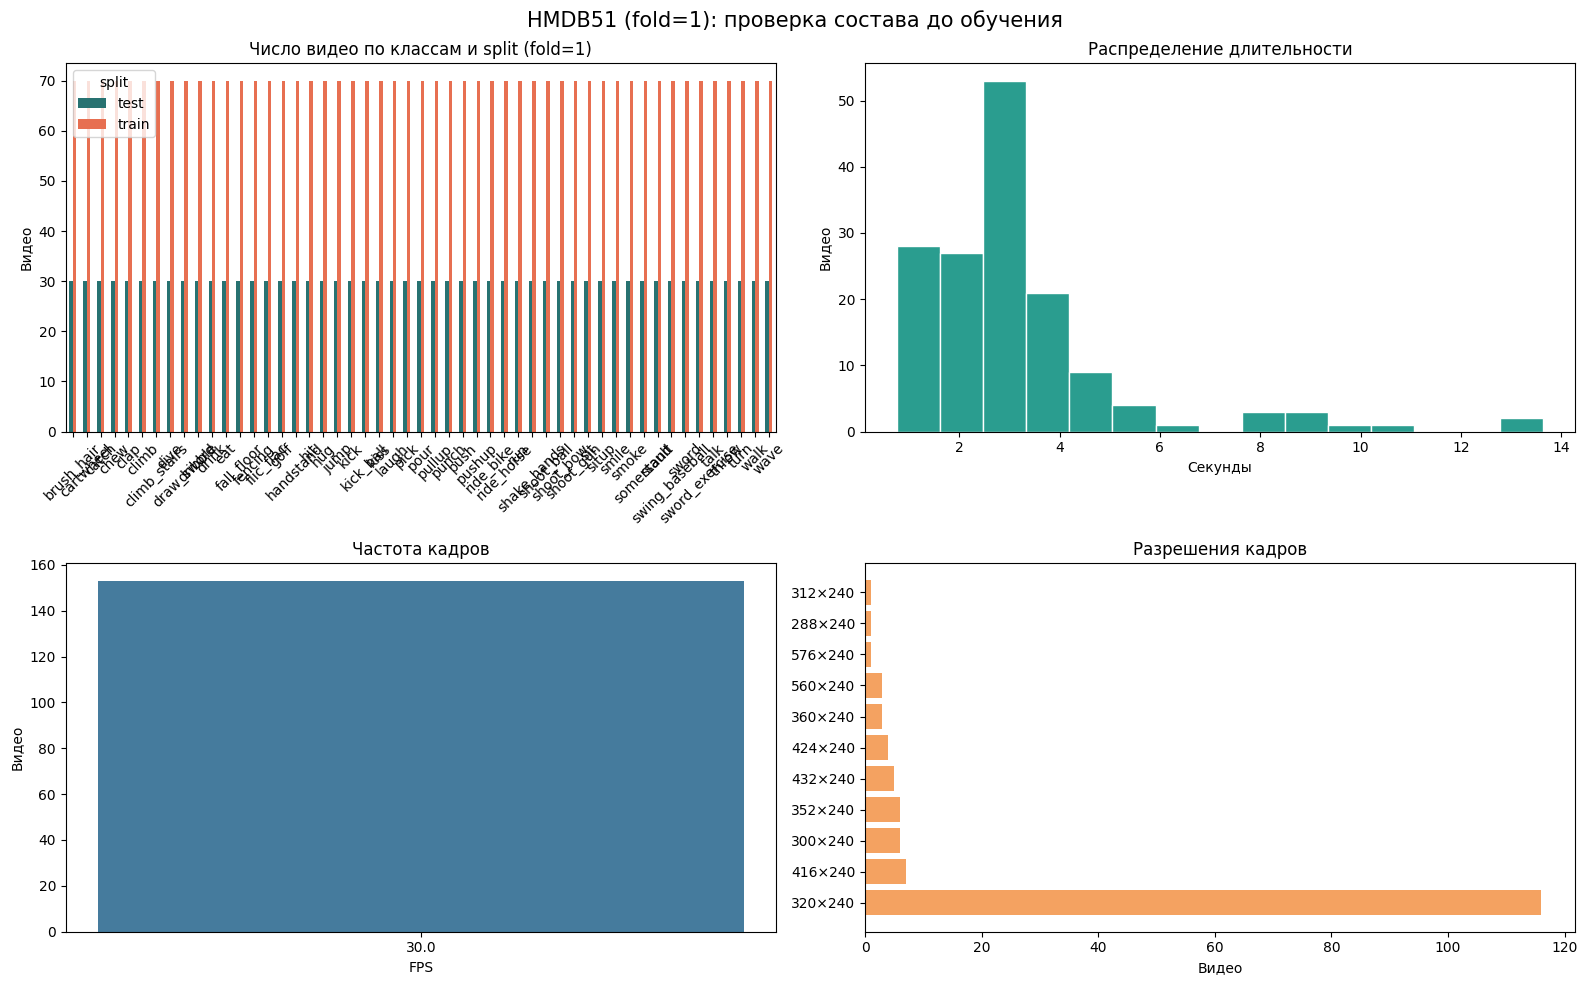

In [10]:
FOLD = 1

CLASS_NAMES = sorted(p.name for p in HMDB_ROOT.iterdir() if p.is_dir())
print("classes:", len(CLASS_NAMES))

def read_split(cls: str, split_name: str, fold: int = FOLD) -> list[str]:
    '''return the class files from orig.txt'''
    txt = HMDB_SPLITS / f"{cls}_test_split{fold}.txt"
    label = 1 if split_name == "train" else 2
    return [
        line.split()[0]
        for line in txt.read_text().strip().splitlines()
        if line.split()[1] == str(label)
    ]

rows = []
for split in ("train", "test"):
    for cls in CLASS_NAMES:
        files = read_split(cls, split, fold=FOLD)
        rows.append({"split": split, "class": cls, "videos": len(files)})

class_counts = pd.DataFrame(rows)
metadata_paths = []
for cls in CLASS_NAMES:
    files = sorted((HMDB_ROOT / cls).glob("*.avi"))[:3]
    metadata_paths.extend(files)

metadata_visual = pd.DataFrame(probe_video(p) for p in tqdm(metadata_paths))

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

class_counts.pivot(index="class", columns="split", values="videos").plot(
    kind="bar", ax=axes[0, 0], color=["#287271", "#E76F51"],
)
axes[0, 0].set_title("Число видео по классам и split (fold=1)")
axes[0, 0].set_xlabel("")
axes[0, 0].set_ylabel("Видео")
axes[0, 0].tick_params(axis="x", rotation=45)

axes[0, 1].hist(
    metadata_visual["duration_s"].dropna(), bins=15,
    color="#2A9D8F", edgecolor="white",
)
axes[0, 1].set_title("Распределение длительности")
axes[0, 1].set_xlabel("Секунды")
axes[0, 1].set_ylabel("Видео")

fps_counts = metadata_visual["fps"].round(2).value_counts().sort_index()
axes[1, 0].bar(fps_counts.index.astype(str), fps_counts.values, color="#457B9D")
axes[1, 0].set_title("Частота кадров")
axes[1, 0].set_xlabel("FPS")
axes[1, 0].set_ylabel("Видео")

resolution_counts = (
    metadata_visual.assign(
        resolution=lambda f: f["width"].astype(str) + "×" + f["height"].astype(str)
    )["resolution"].value_counts()
)
axes[1, 1].barh(resolution_counts.index, resolution_counts.values, color="#F4A261")
axes[1, 1].set_title("Разрешения кадров")
axes[1, 1].set_xlabel("Видео")

fig.suptitle("HMDB51 (fold=1): проверка состава до обучения", fontsize=15)
fig.tight_layout()
display(class_counts.pivot(index="class", columns="split", values="videos"))

In [ ]:
from transformers import VideoMAEForVideoClassification

IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 1, 3, 1, 1)
IMAGENET_STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 1, 3, 1, 1)
X3D_MEAN = torch.tensor([0.45, 0.45, 0.45]).view(1, 1, 3, 1, 1)
X3D_STD = torch.tensor([0.225, 0.225, 0.225]).view(1, 1, 3, 1, 1)


class ResNetMeanEncoder(nn.Module):
    '''ImageNet ResNet-50 applied per frame, followed by temporal mean.'''

    def __init__(self) -> None:
        super().__init__()
        self.backbone = resnet50(weights=ResNet50_Weights.IMAGENET1K_V2)
        self.backbone.fc = nn.Identity()
        self.output_dim = 2048

    def forward(self, clips: torch.Tensor) -> torch.Tensor:
        b, t, c, h, w = clips.shape

        if clips.dtype == torch.uint8:
            clips = clips.float() / 255.0
        
        x = (clips - IMAGENET_MEAN.to(clips)) / IMAGENET_STD.to(clips)
        
        features = self.backbone(x.reshape(b * t, c, h, w))
        return features.view(b, t, -1).mean(dim=1)

class VideoMAEFineTune(nn.Module):
    def __init__(
        self,
        num_classes: int,
        class_names: list[str],                          # ← добавить
        checkpoint: str = "MCG-NJU/videomae-base-finetuned-kinetics",
    ):
        super().__init__()
        id2label = {i: name for i, name in enumerate(class_names)}
        label2id = {name: i for i, name in id2label.items()}
        print(len(id2label))
        self.backbone = VideoMAEForVideoClassification.from_pretrained(
            checkpoint,
            num_labels=num_classes,
            id2label=id2label,                           
            label2id=label2id,                         
            ignore_mismatched_sizes=True,
        )

    def forward(self, clips):
        if clips.dtype == torch.uint8:
            clips = clips.float() / 255.0
        x = (clips - IMAGENET_MEAN.to(clips)) / IMAGENET_STD.to(clips)
        return self.backbone(pixel_values=x).logits


class X3DFineTune(nn.Module):
    '''wrapper around x3d'''

    def __init__(self, num_classes: int):
        super().__init__()
        self.backbone = torch.hub.load(
            "facebookresearch/pytorchvideo", "x3d_s",
            pretrained=True, trust_repo=True,
        )
        in_features = self.backbone.blocks[-1].proj.in_features
        self.backbone.blocks[-1].proj = nn.Linear(in_features, num_classes)

    def forward(self, clips):
        if clips.dtype == torch.uint8:
            clips = clips.float() / 255.0
        
        b, t, c, h, w = clips.shape
        x = F.interpolate(
            clips.reshape(b * t, c, h, w), size=(160, 160),
            mode="bilinear", align_corners=False,
        ).view(b, t, c, 160, 160)
        x = (x - X3D_MEAN.to(x)) / X3D_STD.to(x)
        return self.backbone(x.permute(0, 2, 1, 3, 4))

class X3DEncoder(nn.Module):
    def __init__(self, ckpt: str, num_classes: int):
        super().__init__()
        model = X3DFineTune(num_classes)
        in_features = model.backbone.blocks[-1].proj.in_features 
        model.load_state_dict(torch.load(ckpt, map_location="cpu"))
        model.backbone.blocks[-1].proj = nn.Identity()
        self.backbone = model
        self.output_dim = in_features

    def forward(self, clips):
        return self.backbone(clips)

def build_videomae_for_finetune(num_classes, checkpoint="MCG-NJU/videomae-base"):
    model = VideoMAEForVideoClassification.from_pretrained(
        checkpoint, num_labels=num_classes, ignore_mismatched_sizes=True,
    )
    return model.to(DEVICE)


def build_encoder(name: str, ckpt=None) -> nn.Module:
    if name == "resnet50_mean":
        return ResNetMeanEncoder().eval().to(DEVICE)
    elif name == "x3d-s":
        if ckpt is None:
            raise ValueError("x3d-s требует ckpt")
        return X3DEncoder(ckpt=ckpt, num_classes=51).eval().to(DEVICE)
    else:
        raise KeyError(f"Unknown encoder: {name}")
    

@torch.inference_mode()
def evaluate_finetuned(
    model: nn.Module,
    loader: DataLoader,
) -> tuple[np.ndarray, np.ndarray, np.ndarray, list[str]]:
    '''Returns (probabilities, true_labels, predicted_labels, paths).'''
    model.eval()
    probabilities, labels, paths = [], [], []
    for clips, batch_labels, batch_paths in tqdm(loader, leave=False):
        clips = clips.to(DEVICE, non_blocking=True)
        logits = model(clips)
        probabilities.append(logits.softmax(dim=-1).cpu().numpy())
        labels.append(batch_labels.numpy())
        paths.extend(batch_paths)
    probs = np.concatenate(probabilities)
    true = np.concatenate(labels)
    return probs, true, probs.argmax(axis=1), paths




In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import pandas as pd
from tqdm import tqdm
from sklearn.metrics import accuracy_score
from transformers import get_cosine_schedule_with_warmup


def fine_tune(
    model: nn.Module,
    train_loader,
    val_loader,
    *,
    epochs: int = 10,
    accumulation: int = 16,
    lr: float = 5e-5,
    weight_decay: float = 0.05,
    warmup_ratio: float = 0.1,
    grad_clip: float = 1.0,
    label: str = "model",
    ckpt_dir=None,
) -> tuple[nn.Module, pd.DataFrame]:
    
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=lr, weight_decay=weight_decay,
    )

    num_steps = len(train_loader) * epochs // accumulation
    scheduler = get_cosine_schedule_with_warmup(
        optimizer,
        num_warmup_steps=int(warmup_ratio * num_steps),
        num_training_steps=num_steps,
    )

    scaler = torch.amp.GradScaler("cuda", enabled=DEVICE.type == "cuda")
    history = []
    best_val = 0.0

    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad(set_to_none=True)
        total_loss, n_batches = 0.0, 0

        pbar = tqdm(train_loader, desc=f"epoch {epoch+1}/{epochs}")
        for step, (clips, labels, _) in enumerate(pbar, 1):
            clips = clips.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            with torch.autocast(device_type=DEVICE.type, enabled=DEVICE.type == "cuda"):
                logits = model(clips)
                loss = F.cross_entropy(logits, labels)
                scaled_loss = loss / accumulation

            scaler.scale(scaled_loss).backward()

            if step % accumulation == 0 or step == len(train_loader):
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=grad_clip)

                scale_before = scaler.get_scale()
                scaler.step(optimizer)
                scaler.update()
                scale_after = scaler.get_scale()

                if scale_after >= scale_before:
                    scheduler.step()

                optimizer.zero_grad(set_to_none=True)

            total_loss += float(loss.detach())
            n_batches += 1
            pbar.set_postfix({"loss": f"{loss.item():.3f}"})

        model.eval()
        pred, true = [], []
        with torch.inference_mode():
            for clips, labels, _ in val_loader:
                clips = clips.to(DEVICE, non_blocking=True)
                logits = model(clips)
                pred.extend(logits.argmax(1).cpu().tolist())
                true.extend(labels.tolist())

        val_acc = accuracy_score(true, pred)
        history.append({
            "epoch": epoch + 1,
            "train_loss": total_loss / max(n_batches, 1),
            "val_accuracy": val_acc,
            "lr": optimizer.param_groups[0]["lr"],
        })

        if ckpt_dir is not None:
            if (epoch + 1) % 5 == 0:
                torch.save(
                    {
                        "epoch": epoch,
                        "model": model.state_dict(),
                        "optimizer": optimizer.state_dict(),
                        "scheduler": scheduler.state_dict(),
                        "scaler": scaler.state_dict(),
                    },
                    ckpt_dir / f"{label}_epoch{epoch+1}.pt",
                )
            if val_acc > best_val:
                best_val = val_acc
                torch.save(model.state_dict(), ckpt_dir / f"{label}_best.pt")

    return model, pd.DataFrame(history)

#### Полный файнтюнинг VideoMAE-B + X3D-s


In [14]:
# clips, labels, _ = next(iter(train_loader_x3d))
# print("clips:", clips.shape, clips.dtype)
# print("range:", clips.min().item(), clips.max().item())
# # ожидается: (B, 13, 3, 160, 160), float32, [0, 1]

In [ ]:
BATCH_VIDEOMAE = 16
BATCH_X3D = 64
EFFECTIVE_BATCH = 64

accum_videomae = EFFECTIVE_BATCH // BATCH_VIDEOMAE
accum_x3d = EFFECTIVE_BATCH // BATCH_X3D

CKPT_DIR = Path("kaggle/working/ckpts")
CKPT_DIR.mkdir(parents=True, exist_ok=True)

NUM_WORKERS = 4

train_loader_videomae = DataLoader(train_ds_videomae, batch_size=BATCH_VIDEOMAE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=True)
val_loader_videomae = DataLoader(val_ds_videomae, batch_size=BATCH_VIDEOMAE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)
test_loader_videomae = DataLoader(test_ds_videomae, batch_size=BATCH_VIDEOMAE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)

train_loader_x3d = DataLoader(train_ds_x3d, batch_size=BATCH_X3D, shuffle=True, num_workers=NUM_WORKERS, pin_memory=True)
val_loader_x3d = DataLoader(val_ds_x3d, batch_size=BATCH_X3D, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)
test_loader_x3d = DataLoader(test_ds_x3d, batch_size=BATCH_X3D, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)


model_x3d = X3DFineTune(num_classes=51).to(DEVICE)
model_x3d.load_state_dict(torch.load(MODEL_X3D_CKPT))

# логика обучения
# model_x3d, hist_x = fine_tune(
#     model_x3d, train_loader_x3d,
#     val_loader_x3d, epochs=10,
#     accumulation=accum_x3d, label="x3d", ckpt_dir=CKPT_DIR
# )

x3d_probs, x3d_true, x3d_pred, x3d_paths = evaluate_finetuned(model_x3d, test_loader_x3d)

torch.cuda.empty_cache()

model_videomae = VideoMAEFineTune(num_classes=51, class_names=CLASS_NAMES).to(DEVICE)
model_videomae.load_state_dict(torch.load(MODEL_VIDEOMAE_CKPT))

# логика обучения
# model_videomae, hist_v = fine_tune(
#     model_videomae, train_loader_videomae,
#     val_loader_videomae, epochs=10,
#     accumulation=accum_videomae, label="videomae", ckpt_dir=CKPT_DIR
# )

vm_probs, vm_true, vm_pred, vm_paths = evaluate_finetuned(model_videomae, test_loader_videomae)

torch.cuda.empty_cache()

Using cache found in /root/.cache/torch/hub/facebookresearch_pytorchvideo_main


51


[transformers] You passed `num_labels=51` which is incompatible to the `id2label` map of length `400`.


Loading weights:   0%|          | 0/162 [00:00<?, ?it/s]

[transformers] VideoMAEForVideoClassification LOAD REPORT from: MCG-NJU/videomae-base-finetuned-kinetics
Key                                                            | Status     |                                                                                          
---------------------------------------------------------------+------------+------------------------------------------------------------------------------------------
videomae.encoder.layer.{0...11}.attention.attention.q_bias     | UNEXPECTED |                                                                                          
videomae.encoder.layer.{0...11}.attention.attention.v_bias     | UNEXPECTED |                                                                                          
videomae.encoder.layer.{0...11}.attention.attention.query.bias | MISSING    |                                                                                          
videomae.encoder.layer.{0...11}.attention.attention.val

In [16]:
# print("num_labels:", model_videomae.config.num_labels)        # 51
# print("len(id2label):", len(model_videomae.config.id2label))  # 400 (несоответствие!)
# print("classifier:", model_videomae.classifier)

Сравнение результатов обучения + оценка на тесте + confusion matrix

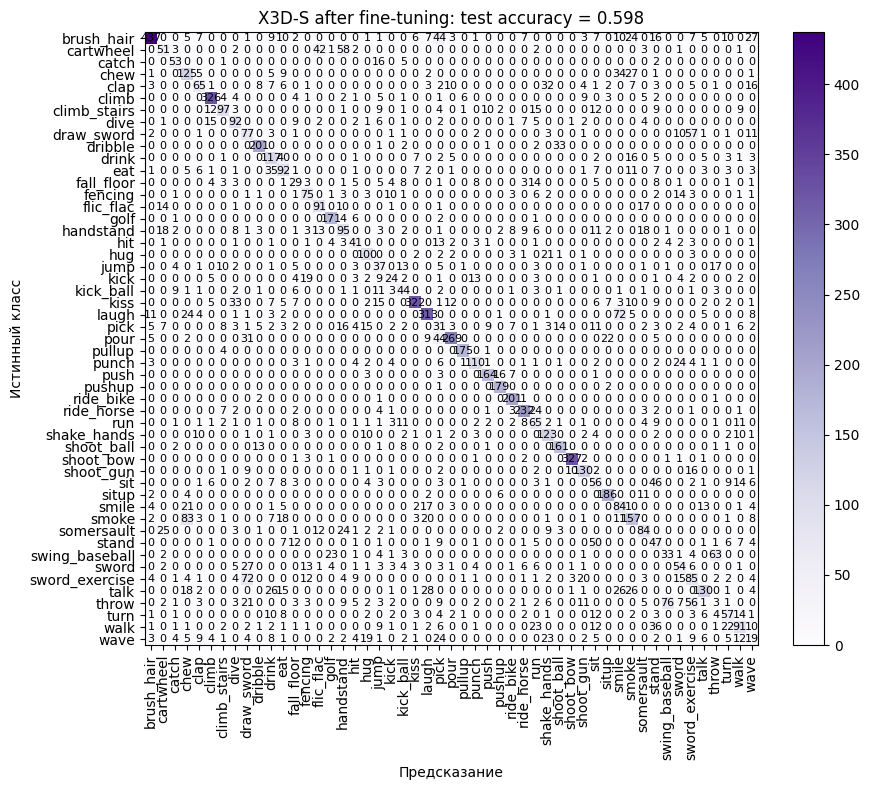

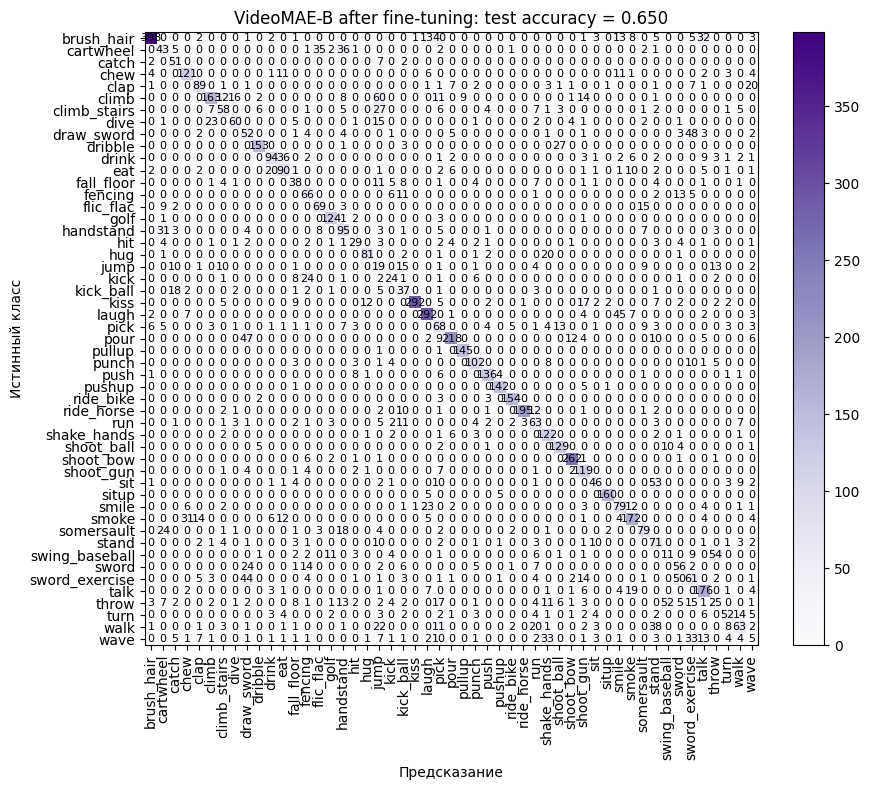

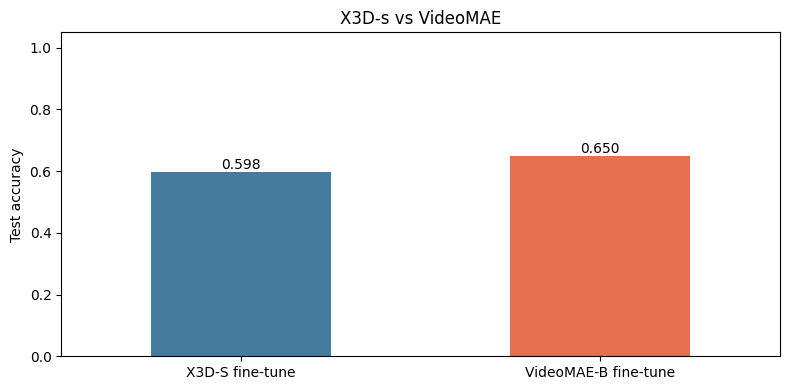

,режим,accuracy
0,X3D-S fine-tune,0.598449
1,VideoMAE-B fine-tune,0.649773


In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from tqdm import tqdm
from sklearn.metrics import accuracy_score, confusion_matrix


def plot_training_curves(history: pd.DataFrame, title: str):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(history["epoch"], history["train_loss"], marker="o")
    axes[0].set_title("Train loss")
    axes[0].set_xlabel("Эпоха")
    axes[0].set_ylabel("Cross-entropy")
    axes[0].grid(alpha=0.25)

    axes[1].plot(
        history["epoch"], history["val_accuracy"],
        marker="o", color="#E76F51",
    )
    axes[1].set_title("Validation accuracy")
    axes[1].set_xlabel("Эпоха")
    axes[1].set_ylim(0, 1.05)
    axes[1].grid(alpha=0.25)

    fig.suptitle(title)
    fig.tight_layout()
    plt.show()



def plot_confusion_matrix(
    true: np.ndarray,
    pred: np.ndarray,
    class_names: list[str],
    title: str,
    cmap: str = "Purples",
):
    matrix = confusion_matrix(true, pred, labels=np.arange(len(class_names)))
    accuracy = accuracy_score(true, pred)

    fig, ax = plt.subplots(figsize=(9, 8))
    image = ax.imshow(matrix, cmap=cmap)
    ax.set_xticks(range(len(class_names)), class_names, rotation=90)
    ax.set_yticks(range(len(class_names)), class_names)
    ax.set_xlabel("Предсказание")
    ax.set_ylabel("Истинный класс")
    ax.set_title(f"{title}: test accuracy = {accuracy:.3f}")
    for row in range(matrix.shape[0]):
        for col in range(matrix.shape[1]):
            ax.text(col, row, matrix[row, col],
                    ha="center", va="center", fontsize=8)
    fig.colorbar(image, ax=ax, fraction=0.046)
    fig.tight_layout()
    plt.show()
    return accuracy


def plot_comparison(
    results: list[dict],
    title: str = "X3D-s vs VideoMAE",
):
    df = pd.DataFrame(results)
    ax = df.plot(
        kind="bar", x="режим", y="accuracy", legend=False,
        figsize=(8, 4), ylim=(0, 1.05),
        color=["#457B9D", "#E76F51", "#2A9D8F"][:len(df)],
    )
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel("Test accuracy")
    ax.tick_params(axis="x", rotation=0)
    for container in ax.containers:
        ax.bar_label(container, fmt="%.3f")
    plt.tight_layout()
    plt.show()
    return df


# X3D
# plot_training_curves(hist_x, "Динамика fine-tuning X3D-S")

x3d_probs, x3d_true, x3d_pred, _ = evaluate_finetuned(model_x3d, test_loader_x3d)
x3d_acc = plot_confusion_matrix(x3d_true, x3d_pred, CLASS_NAMES, "X3D-S after fine-tuning")

# VideoMAE
# plot_training_curves(hist_v, "Динамика fine-tuning VideoMAE-B")

vm_probs, vm_true, vm_pred, _ = evaluate_finetuned(model_videomae, test_loader_videomae)
vm_acc = plot_confusion_matrix(vm_true, vm_pred, CLASS_NAMES, "VideoMAE-B after fine-tuning")

# Comparison
results = [
    {"режим": "X3D-S fine-tune", "accuracy": x3d_acc},
    {"режим": "VideoMAE-B fine-tune", "accuracy": vm_acc},
]

comparison = plot_comparison(results)
display(comparison)

In [20]:
def decode_video(path: Path) -> np.ndarray:
    '''Decode a video to uint8 RGB frames with shape [N, H, W, C].'''
    frames: list[np.ndarray] = []
    with av.open(str(path)) as container:
        for frame in container.decode(video=0):
            frames.append(frame.to_rgb().to_ndarray())
    if not frames:
        raise ValueError(f"No frames decoded from {path}")
    return np.stack(frames)

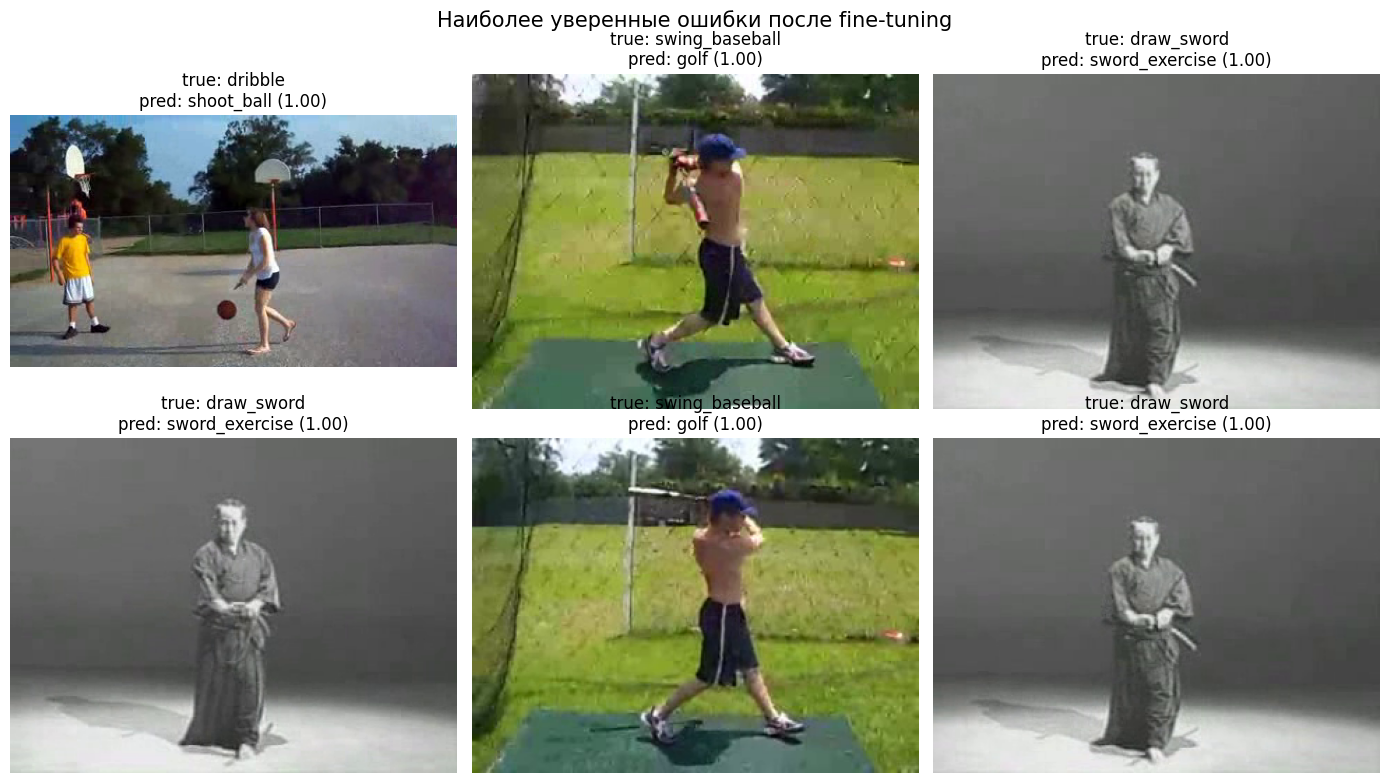

In [21]:
def errors_and_confs(probs, pred, true, paths):
    error_indices = np.flatnonzero(pred != true)
    if len(error_indices) == 0:
        # Если ошибок нет, показываем наименее уверенные правильные ответы.
        error_indices = np.argsort(probs.max(axis=1))[:6]
        gallery_title = "Наименее уверенные правильные ответы"
    else:
        # Сначала показываем самые уверенные ошибки: они наиболее информативны.
        error_indices = error_indices[np.argsort(-probs[error_indices].max(axis=1))][:6]
        gallery_title = "Наиболее уверенные ошибки после fine-tuning"
    
    fig, axes = plt.subplots(2, 3, figsize=(14, 8))
    for ax in axes.flat:
        ax.axis("off")
    for ax, index in zip(axes.flat, error_indices):
        frames = decode_video(Path(paths[index]))
        ax.imshow(frames[len(frames) // 2])
        confidence = probs[index, pred[index]]
        ax.set_title(
            f"true: {CLASS_NAMES[true[index]]}\n"
            f"pred: {CLASS_NAMES[pred[index]]} ({confidence:.2f})"
        )
        ax.axis("off")
    fig.suptitle(gallery_title, fontsize=15)
    fig.tight_layout()

errors_and_confs(x3d_probs, x3d_pred, x3d_true, x3d_paths)

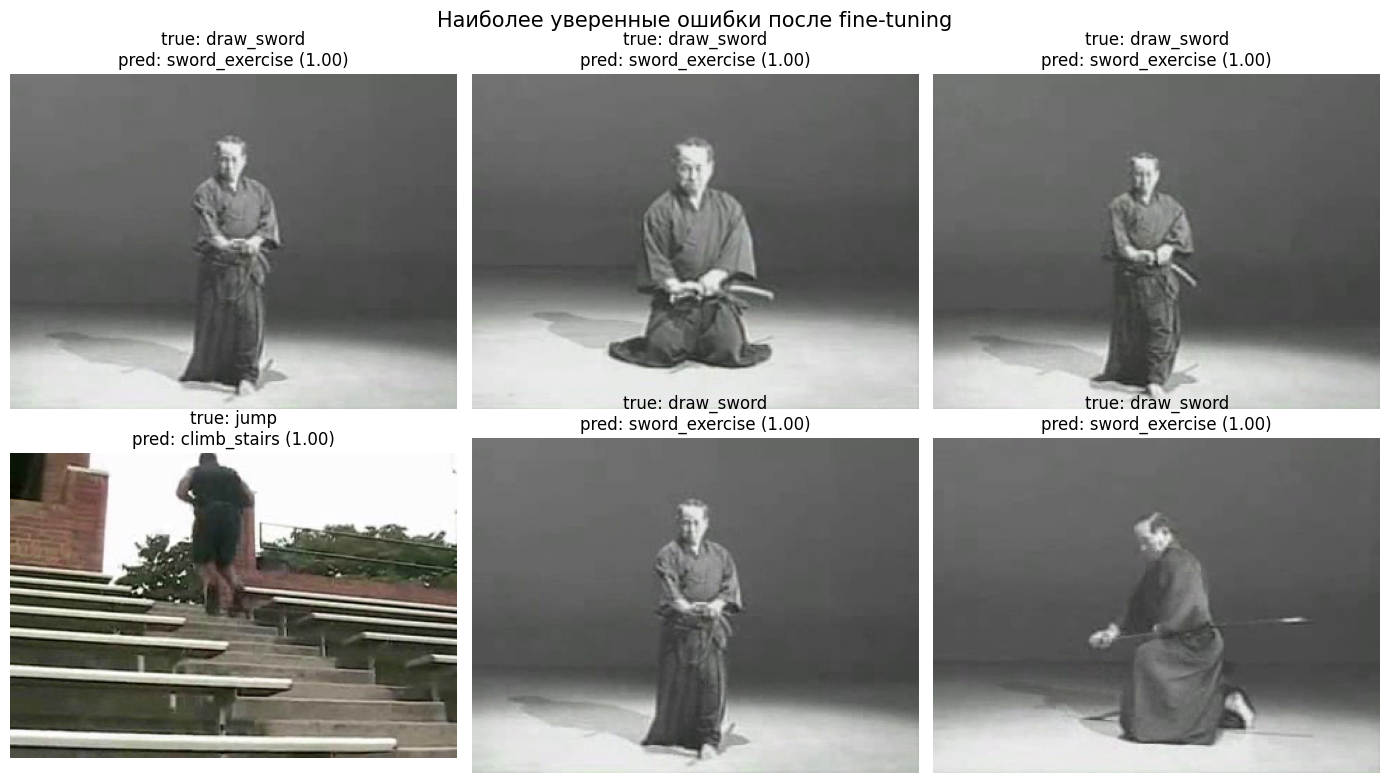

In [22]:
errors_and_confs(vm_probs, vm_pred, vm_true, vm_paths)

In [23]:
def make_loader(
    split: str,
    num_frames: int,
    strategy: str = 'uniform', 
    batch_size: int = 64,
    transform = None
) -> DataLoader:
    
    dataset = HMDB51Dataset(
        root=HMDB_ROOT, annotation_path=HMDB_SPLITS, split=split, num_frames=num_frames, strategy=strategy, transform=transform
    )
    return DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=4, pin_memory=True)

@torch.inference_mode()
def extract_features(model: nn.Module, loader: DataLoader) -> tuple[np.ndarray, np.ndarray, list[str]]:
    '''Extract one feature vector for every clip.'''
    features, labels, paths = [], [], []
    model.eval()
    for clips, y, batch_paths in tqdm(loader, leave=False):
        z = model(clips.to(DEVICE, non_blocking=True))
        features.append(z.cpu().numpy())
        labels.append(y.numpy())
        paths.extend(batch_paths)
    return np.concatenate(features), np.concatenate(labels), paths

def fit_probe(X_train: np.ndarray, y_train: np.ndarray) -> object:
    '''Fit a standardized multinomial logistic-regression head.'''
    return make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000, C=1.0, random_state=SEED),
    ).fit(X_train, y_train)


experiments = [
    {"name": "resnet50_mean", "frames": 1,  "strategy": "uniform",       "ckpt": None,            "gflops": 4.09},
    {"name": "resnet50_mean", "frames": 8,  "strategy": "uniform",       "ckpt": None,            "gflops": 4.09 * 8},
    {"name": "x3d-s",         "frames": 13, "strategy": "repeat_center", "ckpt": MODEL_X3D_CKPT,  "gflops": None},
]

transforms_map = {
    "resnet50_mean": transform_resnet,
    "x3d-s": transform_x3d,
}

probe_rows = []
fitted_probes = {}

for exp in experiments:
    name, frames, strategy = exp["name"], exp["frames"], exp["strategy"]
    transform = transforms_map[name]

    loader_train = make_loader("train", num_frames=frames, strategy=strategy, transform=transform)
    loader_test  = make_loader("test",  num_frames=frames, strategy=strategy, transform=transform)

    model = build_encoder(name, ckpt=exp["ckpt"])
    
    X_train, y_train, _ = extract_features(model, loader_train)
    X_test, y_test,  _ = extract_features(model, loader_test)

    del model
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

    probe = fit_probe(X_train, y_train)
    acc = accuracy_score(y_test, probe.predict(X_test))

    key = f"{name}_t{frames}"
    fitted_probes[key] = probe
    probe_rows.append({
        "model":        name,
        "frames":       frames,
        "strategy":     strategy,
        "feature_dim":  X_train.shape[1],
        "accuracy":     acc,
        "GFLOPs/view":  exp["gflops"],
    })

probe_table = pd.DataFrame(probe_rows)
acc_1 = float(probe_table.loc[probe_table.frames == 1, "accuracy"].iloc[0])
acc_8 = float(probe_table.loc[probe_table.frames == 8, "accuracy"].iloc[0])
print(f"appearance_ratio = {acc_1 / max(acc_8, 1e-12):.3f}")
display(probe_table)


100%|██████████| 423/423 [00:12<00:00, 35.04it/s]


Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 232MB/s]
100%|██████████| 423/423 [00:11<00:00, 38.31it/s]
Using cache found in /root/.cache/torch/hub/facebookresearch_pytorchvideo_main


appearance_ratio = 0.973


,model,frames,strategy,feature_dim,accuracy,GFLOPs/view
0,resnet50_mean,1,uniform,2048,0.465180,4.09
1,resnet50_mean,8,uniform,2048,0.478297,32.72
2,x3d-s,13,repeat_center,2048,0.444193,NaN


In [24]:
x3d_model = X3DFineTune(num_classes=51)
x3d_model.load_state_dict(torch.load(MODEL_X3D_CKPT, map_location="cpu"))
x3d_model = x3d_model.eval().to(DEVICE)

loader_repeat = make_loader("test", num_frames=13, strategy="repeat_center", transform=transform_x3d)
x3d_repeat_probs, x3d_repeat_true, x3d_repeat_pred, x3d_repeat_paths = evaluate_finetuned(
    x3d_model, loader_repeat
)
del x3d_model
torch.cuda.empty_cache()

Using cache found in /root/.cache/torch/hub/facebookresearch_pytorchvideo_main
100%|██████████| 423/423 [00:15<00:00, 27.53it/s]


In [ ]:
fitted_probes

100%|██████████| 423/423 [00:11<00:00, 38.13it/s]


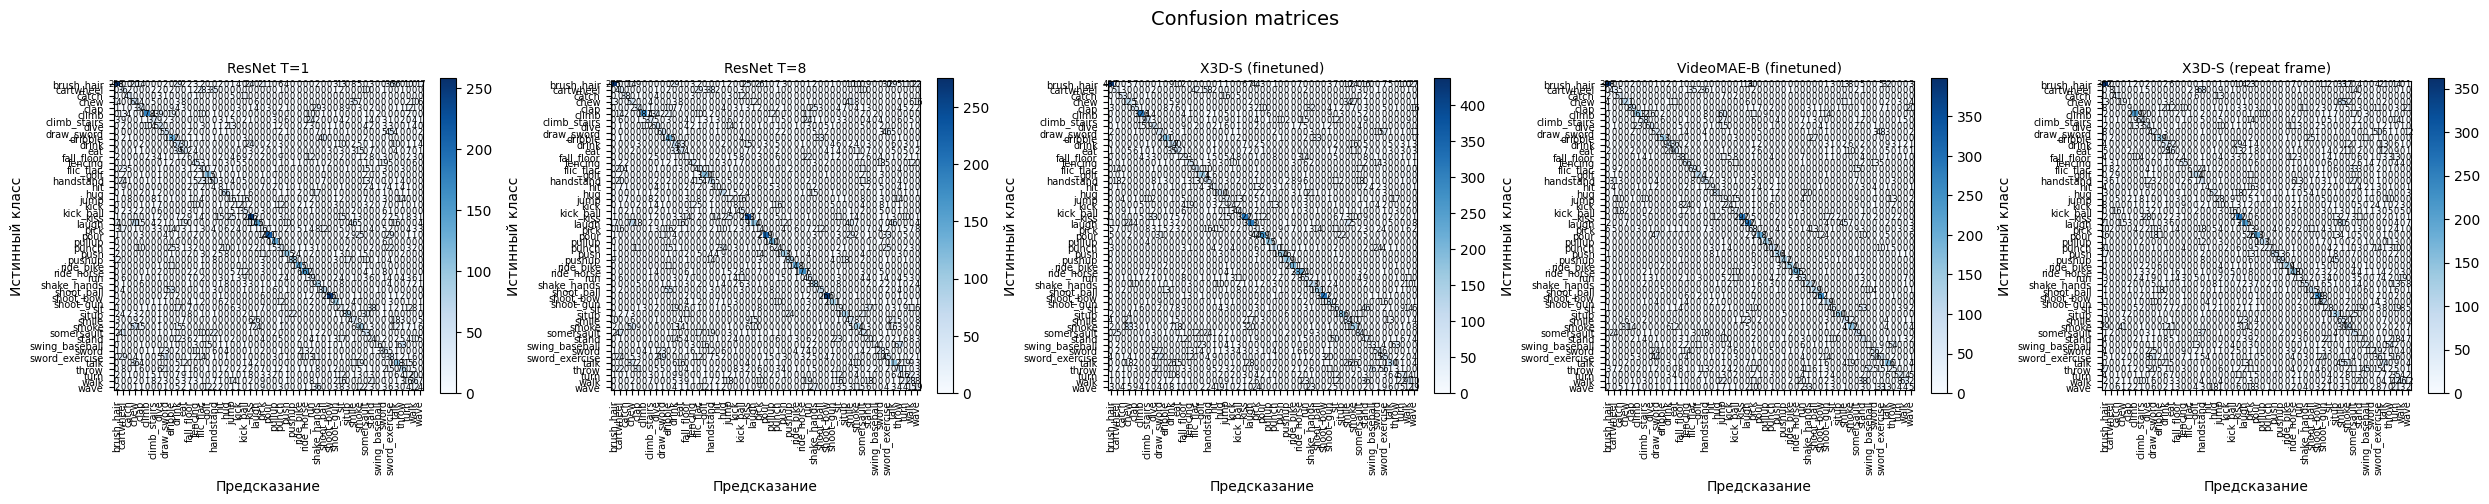

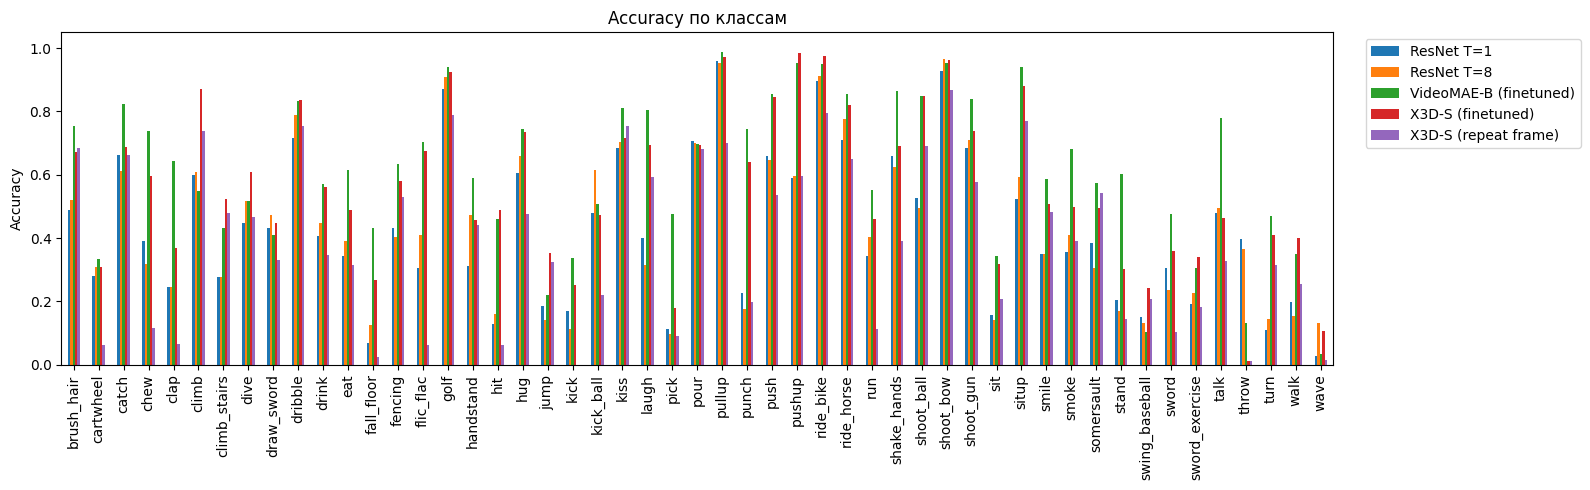

model,ResNet T=1,ResNet T=8,VideoMAE-B (finetuned),X3D-S (finetuned),X3D-S (repeat frame)
class,,,,,
brush_hair,0.49,0.52,0.75,0.67,0.69
cartwheel,0.28,0.31,0.33,0.31,0.06
catch,0.66,0.61,0.82,0.69,0.66
chew,0.39,0.32,0.74,0.60,0.12
clap,0.25,0.25,0.64,0.37,0.07
climb,0.60,0.61,0.55,0.87,0.74
climb_stairs,0.28,0.28,0.43,0.52,0.48
dive,0.45,0.52,0.52,0.61,0.47
draw_sword,0.43,0.47,0.41,0.45,0.33



Глобальный r = 25.128
Глобальный r (точный) = 0.763

Классы где движение важно (r низкий):
class
kick          0.000000
fall_floor    0.084639
flic_flac     0.090828
wave          0.129220
hit           0.130081

Классы где appearance достаточен (r высокий):
class
handstand     0.965544
pour          0.979025
brush_hair    1.019780
kiss          1.053554
somersault    1.099896


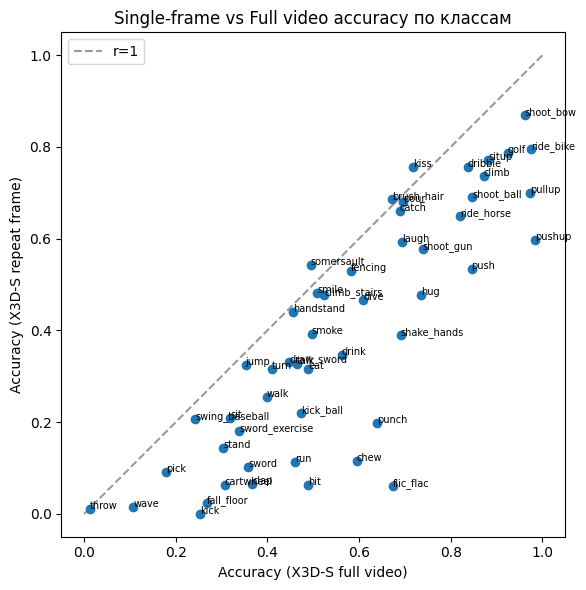

In [ ]:
diagnostics = {}

# ResNet T=1
model_r1 = build_encoder("resnet50_mean")
loader_r1 = make_loader("test", num_frames=1, strategy="uniform", transform=transform_resnet)
X_r1, y_r1, paths_r1 = extract_features(model_r1, loader_r1)
del model_r1
diagnostics["ResNet T=1"] = {"y": y_r1, "pred": fitted_probes["resnet50_mean_t1"].predict(X_r1), "paths": paths_r1}

# ResNet T=8
model_r8 = build_encoder("resnet50_mean")
loader_r8 = make_loader("test", num_frames=8, strategy="uniform", transform=transform_resnet)
X_r8, y_r8, paths_r8 = extract_features(model_r8, loader_r8)
del model_r8
diagnostics["ResNet T=8"] = {"y": y_r8, "pred": fitted_probes["resnet50_mean_t8"].predict(X_r8), "paths": paths_r8}

# Файнтюненные модели
diagnostics["X3D-S (finetuned)"] = {"y": x3d_true, "pred": x3d_pred, "paths": x3d_paths}
diagnostics["VideoMAE-B (finetuned)"] = {"y": vm_true, "pred": vm_pred, "paths": vm_paths}
diagnostics["X3D-S (repeat frame)"] = {"y": x3d_repeat_true, "pred": x3d_repeat_pred, "paths": x3d_repeat_paths}

n_models = len(diagnostics)

fig, axes = plt.subplots(1, n_models, figsize=(5 * n_models, 5), squeeze=False)
for ax, (title, values) in zip(axes[0], diagnostics.items()):
    matrix = confusion_matrix(values["y"], values["pred"], labels=np.arange(len(CLASS_NAMES)))
    img = ax.imshow(matrix, cmap="Blues")
    ax.set_title(title, fontsize=10)
    ax.set_xticks(range(len(CLASS_NAMES)), CLASS_NAMES, rotation=90, fontsize=7)
    ax.set_yticks(range(len(CLASS_NAMES)), CLASS_NAMES, fontsize=7)
    ax.set_xlabel("Предсказание")
    ax.set_ylabel("Истинный класс")
    for r in range(matrix.shape[0]):
        for c in range(matrix.shape[1]):
            ax.text(c, r, matrix[r, c], ha="center", va="center", fontsize=6)
    fig.colorbar(img, ax=ax, fraction=0.046)
fig.suptitle("Confusion matrices", fontsize=14)
fig.tight_layout()
plt.show()


per_class_rows = []
for title, values in diagnostics.items():
    for cls_idx, cls_name in enumerate(CLASS_NAMES):
        mask = values["y"] == cls_idx
        per_class_rows.append({
            "model": title,
            "class": cls_name,
            "accuracy": float(np.mean(values["pred"][mask] == cls_idx)) if mask.sum() > 0 else 0.0,
        })

per_class_table = pd.DataFrame(per_class_rows).pivot(
    index="class", columns="model", values="accuracy"
)

ax = per_class_table.plot(kind="bar", figsize=(16, 5), ylim=(0, 1.05))
ax.set_title("Accuracy по классам")
ax.set_ylabel("Accuracy")
ax.set_xlabel("")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()
display(per_class_table.round(2))


r_per_class = (
    per_class_table["X3D-S (repeat frame)"] /
    per_class_table["X3D-S (finetuned)"].replace(0, np.nan)
).dropna().sort_values()

print(f"\nГлобальный r = {x3d_repeat_pred.mean():.3f}")  # грубо
print(f"Глобальный r (точный) = {(x3d_repeat_true == x3d_repeat_pred).mean() / (x3d_true == x3d_pred).mean():.3f}")

print("\nКлассы где движение важно (r низкий):")
print(r_per_class.head(5).to_string())

print("\nКлассы где appearance достаточен (r высокий):")
print(r_per_class.tail(5).to_string())

# scatter: single-frame vs full video accuracy по классам
fig, ax = plt.subplots(figsize=(6, 6))
x_vals = per_class_table["X3D-S (finetuned)"]
y_vals = per_class_table["X3D-S (repeat frame)"]
ax.scatter(x_vals, y_vals, zorder=3)
for cls_name in CLASS_NAMES:
    ax.annotate(cls_name, (x_vals[cls_name], y_vals[cls_name]), fontsize=7)
lims = [0, 1]
ax.plot(lims, lims, "k--", alpha=0.4, label="r=1")
ax.set_xlabel("Accuracy (X3D-S full video)")
ax.set_ylabel("Accuracy (X3D-S repeat frame)")
ax.set_title("Single-frame vs Full video accuracy по классам")
ax.legend()
plt.tight_layout()
plt.show()

#### Если класс является объектом, позой или контекстом -- appearance достаточен. Если же класс определяется направленим, скоростью или траекторией, то нужна временная составляющая.